# Quick start: from a material to a fitted measurement

This notebook simulates one Bragg-edge transmission measurement with four
overlapping pulses per period and analyses it in two ways:

* the **Rietveld fit of the overlapped spectrum**: the nbragg model is passed
  through the known pulse pattern and fitted to the counts, and
* **Wiener deconvolution** as in frame-overlap Bragg-edge imaging (FOBI),
  followed by a fit of the recovered transmission.

The material is described exactly as in nbragg.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import nbragg
import frame_overlap as fo

# the material, as in nbragg: 2 cm of alpha-iron
xs = nbragg.CrossSection(materials={"iron": {"mat": "Fe_sg229_Iron-alpha.ncmat"}})
model = nbragg.TransmissionModel(xs, response="jorgensen_inv", tof_length=9.0, vary_response=False)
model.params["thickness"].set(value=2.0)     # cm
model.params["α0"].set(value=3000.0)         # moderator response (rise), close to a water moderator
model.params["β0"].set(value=50.0)           # moderator response (decay)
sample = fo.Sample(model, free=["thickness", "strain"])

# the instrument: 9 m flight path, 50 ms period, 10 us bins, a thermal moderator
grid = fo.TimeGrid(flight_path=9.0, frequency=20.0, bin_width=10e-6)
beam = fo.OpenBeam.maxwellian(grid, flux=5e6, area=0.03)
hours = 8

## The measurement design

A pulse pattern says when the chopper opens within the period. Here: one
200 µs pulse per period, and four pulses at times chosen so that the intense
thermal part of each spectrum avoids the Bragg edges of the others.

In [2]:
one = fo.Pattern.single(200e-6)
four = fo.Pattern.times([0.0, 11.97e-3, 22.33e-3, 35.48e-3], width=200e-6)
exp1 = fo.Experiment(sample, beam, one, time=hours * 3600)
exp4 = fo.Experiment(sample, beam, four, time=hours * 3600)
print(exp4)
print(exp1.precision())    # Cramer-Rao bound: the best any unbiased analysis can do
print(exp4.precision())
print("time-reduction factor of the four pulses:", exp4.gain())

Experiment(Pattern(4 pulses: starts [0.0, 11.97, 22.33, 35.48] ms, widths [200.0] us), 8 h, Sample(free: thickness=2, strain=0))


   parameter  value     sigma  sigma_microstrain
0  thickness    2.0  0.000749                NaN
1     strain    0.0  0.000169         169.021251


   parameter  value     sigma  sigma_microstrain
0  thickness    2.0  0.000432                NaN
1     strain    0.0  0.000086          85.636444
time-reduction factor of the four pulses: {'thickness': np.float64(3.0040104572469595), 'strain': np.float64(3.8955194421864467)}


The time-reduction factor *R* is the factor by which the measurement with
one pulse per period would have to be longer to reach the same precision.

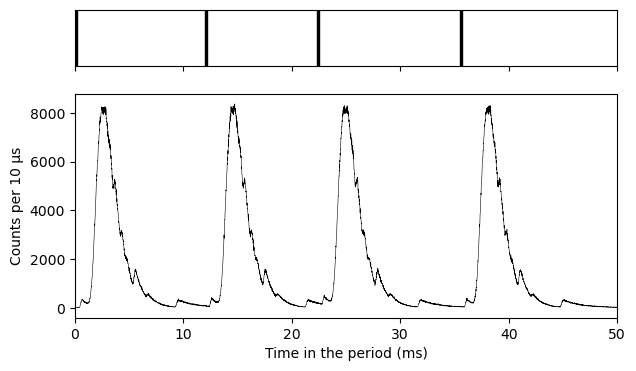

In [3]:
data = exp4.simulate(seed=1)
fig, (a0, a1) = plt.subplots(2, 1, figsize=(7, 4), sharex=True, gridspec_kw=dict(height_ratios=[1, 4]))
four.plot(a0, period=grid.period)
data.plot(a1)
a0.set_xlabel("")
plt.show()

## Rietveld fit of the overlapped spectrum

Rietveld fit: deviance per bin 0.977, converged after 6 evaluations
parameter    value    error  truth  value_microstrain  error_microstrain
thickness 1.999229 0.000432    2.0                NaN                NaN
   strain 0.000089 0.000086    0.0          88.980823          85.672586


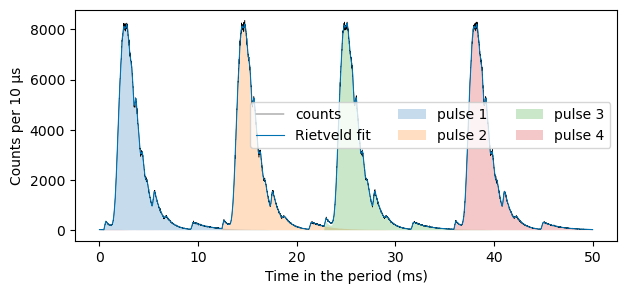

In [4]:
rietveld = fo.RietveldFit(window=(1.0, 5.0)).fit(data, sample)
print(rietveld.summary())
fig, ax = plt.subplots(figsize=(7, 3))
rietveld.plot(ax)
for k, part in enumerate(rietveld.extra["contributions"]):
    ax.fill_between(grid.t * 1e3, 0, part, alpha=0.25, label=f"pulse {k + 1}")
ax.legend(ncol=3)
plt.show()

## Wiener deconvolution (FOBI)

Wiener deconvolution: chi2 per bin 0.166, converged after 11 evaluations
parameter    value    error  truth  value_microstrain  error_microstrain
thickness 1.999892 0.000672    2.0                NaN                NaN
   strain 0.000869 0.000329    0.0         869.239034         328.894068


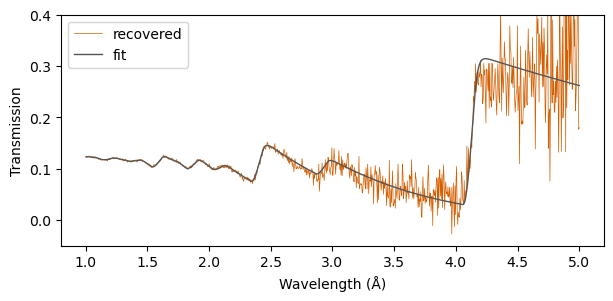

In [5]:
wiener = fo.WienerFit(noise_power=1e-3).fit(data, sample)
print(wiener.summary())
fig, ax = plt.subplots(figsize=(7, 3))
wiener.plot(ax)
ax.set_ylim(-0.05, 0.4)
plt.show()

## Comparison

Both analyses use the same counts. The Rietveld fit reaches the Cramér–Rao
bound; the deconvolution followed by a fit with independent bins does not.

In [6]:
import pandas as pd
bound = exp4.precision().set_index("parameter").sigma
pd.DataFrame({"Cramer-Rao bound": bound,
              "Rietveld fit": pd.Series(rietveld.errors),
              "Wiener deconvolution": pd.Series(wiener.errors)})

,Cramer-Rao bound,Rietveld fit,Wiener deconvolution
thickness,0.000432,0.000432,0.000672
strain,0.000086,0.000086,0.000329
